# Lab 8A — Audio Embeddings and Similarity Search
### AIML ZG527 — Audio Analysis 
**Authored by:** Seetha Parameswaran, BITS Pilani WILP

**Audio retrieval** answers a deceptively simple question: given a sound archive too large
to browse by hand, how do you *find* the clip you want? You cannot search a million `.wav`
files by filename. You need to search them by **content** — by what they actually sound like.

The idea that makes this tractable is to turn every clip into a **vector**, so that
"similar sound" becomes "nearby point", and search becomes **nearest-neighbour geometry**.
This lab builds that system end to end, on a real corpus, and confronts the two things that
break it at scale: the **cost** of naive search, and the **staleness** of a live index.

**The retrieval pipeline built in this lab:**

| Stage | What happens | When |
|-------|--------------|------|
| Encode | Every clip → a fixed-length embedding (YAMNet) | Offline, once |
| Index | Embeddings → a searchable ANN structure | Offline, once |
| Query | A *new, unseen* clip → one vector → ranked results | Online, per request |
| Maintain | Insert, delete, re-index as the corpus changes | Continuous |

**What you will see:**
- Why we **L2-normalise** — cosine, dot product, and Euclidean distance made interchangeable
- Brute-force search, and the exact corpus size at which it **stops being viable**
- A **Flat** index vs an **IVF** index, and the `nprobe` **recall–latency** trade-off curve
- Retrieval **evaluation** — Recall@K, Precision@K, mAP — and why Recall@1 is arithmetically capped
- **Index maintenance** — incremental insert, tombstone-delete, and the encoder change that forces a full re-embed

### Learning Objectives
- Encode audio clips into fixed-length embeddings using YAMNet
- Understand why L2-normalisation makes cosine, dot product, and Euclidean ranking equivalent
- Build and compare Flat and IVF (ANN) indexes, and tune the recall–latency trade-off via `nprobe`
- Evaluate retrieval with Recall@K, Precision@K, and mAP
- Maintain a live index: incremental insert, tombstone-delete, and full re-embed on encoder change

---
### Setup and Import Libraries

`!pip install librosa scikit-learn pandas matplotlib tensorflow-hub faiss-cpu --break-system-packages`

### Dataset: UrbanSound8K
10 classes, 8732 clips, ≤4s each, ~6GB. This lab uses **folds 1–2 only** to keep CPU embedding time to a few minutes.

`> `UrbanSound8K.csv` and the `fold1/ … fold10/` directories sit directly under the dataset root.`



## Step 0. Setup`faiss-cpu` is used for the index. 

If it is not available on the lab machine, the notebook falls back to a NumPy + scikit-learn implementation of the same two index types — the results and the lessons are identical.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
np.random.seed(0)
try:    
    import faiss    
    HAS_FAISS = True
except ImportError:    
    HAS_FAISS = False
    print("FAISS available:", HAS_FAISS)

In [2]:
# ---- Configuration -------------------------------------------------
DATA_ROOT = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/UrbanSound8k"          # CSV and fold dirs sit directly under this root
FOLDS     = [1, 2]                  # keep the demo small
SR        = 16000                   # YAMNet expects 16 kHz mono
MAX_CLIPS = 800                     # cap for demo speed; set to None for all of folds 1-2

## 1. Offline, Step A — load the corpus

The **database** is a fixed collection of audio files, known in advance.

No user and no query is involved yet.

In [3]:
csv_path = os.path.join(DATA_ROOT, "UrbanSound8K.csv")
meta = pd.read_csv(csv_path)
meta = meta[meta["fold"].isin(FOLDS)].reset_index(drop=True)
if MAX_CLIPS:    
    meta = meta.sample(n=min(MAX_CLIPS, len(meta)), random_state=0).reset_index(drop=True)
    meta["path"] = meta.apply(    
        lambda r: os.path.join(DATA_ROOT, f"fold{r['fold']}", r["slice_file_name"]), axis=1)
    print(f"Corpus size N = {len(meta)}")
    print(meta["class"].value_counts())
    meta[["slice_file_name", "fold", "class", "classID"]].head()

Corpus size N = 800
jackhammer          117
street_music        106
air_conditioner      96
siren                88
drilling             88
dog_bark             84
engine_idling        78
children_playing     77
gun_shot             35
car_horn             31
Name: class, dtype: int64


## 2. Offline, Step B — embed every clip

Load YAMNet, run each clip through it, and take the **penultimate layer**(the 1024-d embedding), not the classification head. YAMNet returns **one embedding per 0.96 s frame**. A clip of any length must become a **single fixed-length vector**, so we mean-pool over the frames. Note what mean-pooling destroys: all temporal ordering. This is exactly the limitation — a pooled vector cannot support captioning or counting, only similarity.

In [4]:
import tensorflow_hub as hub
yamnet = hub.load("https://tfhub.dev/google/yamnet/1")
print("YAMNet loaded.")

2026-07-16 10:30:15.632766: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2026-07-16 10:30:15.632791: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-07-16 10:30:18.179441: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2026-07-16 10:30:18.179495: W tensorflow/stream_executor/cuda/cuda_driver.cc:269] failed call to cuInit: UNKNOWN ERROR (303)
2026-07-16 10:30:18.179519: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (seetha-HP-348-G4): /proc/driver/nvidia/version does not exist
2026-07-16 10:30:18.179770: I tensorflow/core/platform/cpu_f

YAMNet loaded.


In [5]:
def embed_clip(path, sr=SR):
    """Return a single 1024-d embedding for one audio file."""
    wav, _ = librosa.load(path, sr=sr, mono=True)    
    if wav.size == 0:        
        return np.zeros(1024, dtype=np.float32)    
    _, embeddings, _ = yamnet(wav)          # embeddings: (n_frames, 1024)    
    return embeddings.numpy().mean(axis=0)  # mean-pool over time

t0 = time.time()
E_raw = np.stack([embed_clip(p) for p in meta["path"]]).astype("float32")
print(f"Embedded {E_raw.shape[0]} clips in {time.time()-t0:.1f}s")
print("Embedding matrix E:", E_raw.shape, "-> N x d")

labels = meta["class"].values
label_ids = meta["classID"].values

Embedded 800 clips in 39.8s
Embedding matrix E: (800, 1024) -> N x d


## 3. The geometry: why we L2-normalise

The slides claimed that **after L2-normalisation**, ranking by cosine, by dot product,and by Euclidean distance give the **same order**.Let us verify that, rather than take it on faith.

In [6]:
def l2_normalize(X):    
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)

E = l2_normalize(E_raw)
q_idx = 0
q_raw, q_norm = E_raw[q_idx], E[q_idx]

# --- BEFORE normalisation: do the three metrics agree?
cos_before  = (E_raw @ q_raw) / (np.linalg.norm(E_raw, axis=1) * np.linalg.norm(q_raw) + 1e-9)
dot_before  = E_raw @ q_raw
euc_before  = -np.linalg.norm(E_raw - q_raw, axis=1)      # negate: higher = closer

# --- AFTER normalisation
cos_after   = E @ q_norm
dot_after   = E @ q_norm
euc_after   = -np.linalg.norm(E - q_norm, axis=1)


def top(scores, k=5):    
    return np.argsort(-scores)[:k]

print("BEFORE L2-normalisation, top-5 ids:")
print("  cosine   :", top(cos_before))
print("  dot      :", top(dot_before), "   <-- differs from cosine")
print("  euclidean:", top(euc_before))
print("AFTER L2-normalisation, top-5 ids:")
print("  cosine   :", top(cos_after))
print("  dot      :", top(dot_after))
print("  euclidean:", top(euc_after), "  <-- all three identical")

BEFORE L2-normalisation, top-5 ids:
  cosine   : [  0 182 379 414 209]
  dot      : [ 70 618 563  82 131]    <-- differs from cosine
  euclidean: [  0 182 379 209 414]
AFTER L2-normalisation, top-5 ids:
  cosine   : [  0 182 379 414 209]
  dot      : [  0 182 379 414 209]
  euclidean: [  0 182 379 414 209]   <-- all three identical


**Read the output.** 

Before normalisation the dot product disagrees with cosine — it is magnitude-sensitive, so a clip whose embedding happens to have a large norm is unfairlypromoted. 

After normalisation all three metrics produce the *same ranking*.

**Consequence:** the index only ever needs to compute **dot products** — the cheapest ofthe three. That is why FAISS's inner-product index is all we need. We also confirm the identity from the slides directly:
$$\|\mathbf{u} - \mathbf{v}\|_2^2 = 2 - 2\,\mathrm{sim}(\mathbf{u}, \mathbf{v})$$

In [7]:
u, v = E[0], E[1]
lhs = np.linalg.norm(u - v) ** 2
rhs = 2 - 2 * np.dot(u, v)

print(f"||u - v||^2 = {lhs:.6f}")
print(f"2 - 2*sim   = {rhs:.6f}")

||u - v||^2 = 1.771447
2 - 2*sim   = 1.771447


## 4. Online — answering a query, by brute force**

The key distinction, made concrete.**
- `E` is the **database**: N vectors, computed offline, sitting in memory.
- `q` is the **query**: *one* vector, computed *now*.

Below we pretend a clip is a new arrival. In a real system the query would be a file thesystem has never seen — it is *not* a row of `E`.

In [8]:
def brute_force_search(E, q, k=5):    
    scores = E @ q               # one dot product against every one of the N vectors    
    ids = np.argsort(-scores)[:k]    
    return ids, scores[ids]

query_i = 3
q = E[query_i]

print(f"QUERY: {meta.loc[query_i, 'slice_file_name']}  (true class: {labels[query_i]})")
print()

ids, scores = brute_force_search(E, q, k=6)
print(f"{'rank':<6}{'id':<7}{'class':<20}{'cosine':<8}")

for r, (i, s) in enumerate(zip(ids, scores)):    
    mark = "  <- the query itself" if i == query_i else ""   
    print(f"{r:<6}{i:<7}{labels[i]:<20}{s:<8.3f}{mark}")

QUERY: 159738-8-0-5.wav  (true class: siren)

rank  id     class               cosine  
0     3      siren               1.000     <- the query itself
1     514    siren               0.959   
2     125    siren               0.943   
3     735    siren               0.939   
4     334    siren               0.912   
5     585    siren               0.910   


## 5. Why we need an index

Brute force costs $O(Nd)$ **per query**. Let us measure it, then extrapolate.

In [9]:
N, d = E.shape
t0 = time.time()

for _ in range(50):    
    _ = brute_force_search(E, q, k=5)
    ms_per_query = (time.time() - t0) / 50 * 1000
    
    print(f"Corpus: N = {N}, d = {d}")
    print(f"Brute-force query latency: {ms_per_query:.2f} ms")
    print()
    print("Extrapolating (cost is linear in N):")
    
    for N_big in [1e3, 1e5, 1e7, 1e9]:    
        est_ms = ms_per_query * (N_big / N)    
        ram_gb = N_big * d * 4 / 1e9    
        verdict = "fine" if est_ms < 50 else ("borderline" if est_ms < 500 else "UNUSABLE")    
        print(f"  N = {N_big:>10.0e}: {est_ms:>10.1f} ms/query, {ram_gb:>7.2f} GB RAM   -> {verdict}")

Corpus: N = 800, d = 1024
Brute-force query latency: 0.09 ms

Extrapolating (cost is linear in N):
  N =      1e+03:        0.1 ms/query,    0.00 GB RAM   -> fine
  N =      1e+05:       11.4 ms/query,    0.41 GB RAM   -> fine
  N =      1e+07:     1135.6 ms/query,   40.96 GB RAM   -> UNUSABLE
  N =      1e+09:   113564.7 ms/query, 4096.00 GB RAM   -> UNUSABLE
Corpus: N = 800, d = 1024
Brute-force query latency: 0.11 ms

Extrapolating (cost is linear in N):
  N =      1e+03:        0.1 ms/query,    0.00 GB RAM   -> fine
  N =      1e+05:       13.7 ms/query,    0.41 GB RAM   -> fine
  N =      1e+07:     1367.4 ms/query,   40.96 GB RAM   -> UNUSABLE
  N =      1e+09:   136739.0 ms/query, 4096.00 GB RAM   -> UNUSABLE
Corpus: N = 800, d = 1024
Brute-force query latency: 0.12 ms

Extrapolating (cost is linear in N):
  N =      1e+03:        0.2 ms/query,    0.00 GB RAM   -> fine
  N =      1e+05:       15.5 ms/query,    0.41 GB RAM   -> fine
  N =      1e+07:     1546.7 ms/query,   40.96 

Corpus: N = 800, d = 1024
Brute-force query latency: 0.74 ms

Extrapolating (cost is linear in N):
  N =      1e+03:        0.9 ms/query,    0.00 GB RAM   -> fine
  N =      1e+05:       92.2 ms/query,    0.41 GB RAM   -> borderline
  N =      1e+07:     9223.8 ms/query,   40.96 GB RAM   -> UNUSABLE
  N =      1e+09:   922375.9 ms/query, 4096.00 GB RAM   -> UNUSABLE
Corpus: N = 800, d = 1024
Brute-force query latency: 0.75 ms

Extrapolating (cost is linear in N):
  N =      1e+03:        0.9 ms/query,    0.00 GB RAM   -> fine
  N =      1e+05:       94.2 ms/query,    0.41 GB RAM   -> borderline
  N =      1e+07:     9424.4 ms/query,   40.96 GB RAM   -> UNUSABLE
  N =      1e+09:   942444.8 ms/query, 4096.00 GB RAM   -> UNUSABLE
Corpus: N = 800, d = 1024
Brute-force query latency: 0.90 ms

Extrapolating (cost is linear in N):
  N =      1e+03:        1.1 ms/query,    0.00 GB RAM   -> fine
  N =      1e+05:      112.2 ms/query,    0.41 GB RAM   -> borderline
  N =      1e+07:    11216.3 

**This is where vector indexing comes from.** It is not a separate topic bolted on — it isthe direct answer to the number printed above. An index is a structure built *over* `E`,offline, so that search touches only a fraction of the N vectors.The price: we no longer guarantee the *exact* nearest neighbour. Hence **ANN** —*Approximate* Nearest Neighbour search.

## 6. Two indexes: Flat and IVF- 

**Flat** — no structure, exhaustive scan. 100% recall. We use it as **ground truth**.- 

**IVF** — k-means the corpus into `nlist` cells; at query time probe only the `nprobe`  nearest cells.

In [10]:
if HAS_FAISS:    
    index_flat = faiss.IndexFlatIP(d)    
    index_flat.add(E)    
    nlist = 32    
    quantizer = faiss.IndexFlatIP(d)    
    index_ivf = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_INNER_PRODUCT)    
    index_ivf.train(E)          # <-- this is the k-means step    
    index_ivf.add(E)    
    
    def search_flat(q, k):        
        s, i = index_flat.search(q.reshape(1, -1), k)        
        return i[0], s[0]    

    def search_ivf(q, k, nprobe): 
        index_ivf.nprobe = nprobe        
        s, i = index_ivf.search(q.reshape(1, -1), k)        
        return i[0], s[0]
else:    # ---- Fallback: the same two indexes, in NumPy + scikit-learn ----    
    
    from sklearn.cluster import KMeans    
    nlist = 32    
    km = KMeans(n_clusters=nlist, n_init=4, random_state=0).fit(E)    
    cell_of = km.labels_    
    centroids = l2_normalize(km.cluster_centers_.astype("float32"))    
    inverted_list = {c: np.where(cell_of == c)[0] for c in range(nlist)}    
    
    def search_flat(q, k):        
        s = E @ q        
        i = np.argsort(-s)[:k]        
        return i, s[i]    
    
    def search_ivf(q, k, nprobe):        
        cells = np.argsort(-(centroids @ q))[:nprobe]        # probe nearest cells only        
        cand = np.concatenate([inverted_list[c] for c in cells])        
        s = E[cand] @ q        
        order = np.argsort(-s)[:k]        
        return cand[order], s[order]
    
    print(f"Flat index: {N} vectors, exhaustive")
    print(f"IVF index : {nlist} cells, ~{N//nlist} vectors per cell")

WARNING clustering 800 points to 32 centroids: please provide at least 1248 training points


## 7. The recall--latency knob

`nprobe` is the single most important tuning parameter of an IVF index.

- **Index recall** = did ANN return what the Flat (exhaustive) index would have returned?- This is *not* the same as semantic quality. It is measured against brute force, not  against human judgement.

In [11]:
K = 10
n_queries = 100
query_ids = np.random.choice(N, n_queries, replace=False)# ground truth from the Flat index
gt = {i: set(search_flat(E[i], K)[0]) for i in query_ids}
rows = []

for nprobe in [1, 2, 4, 8, 16, 32]:    
    hits, t0 = 0, time.time()    
    for i in query_ids:        
        got, _ = search_ivf(E[i], K, nprobe)        
        hits += len(gt[i] & set(got))    
        lat = (time.time() - t0) / n_queries * 1000    
        rows.append({"nprobe": nprobe,                 
                     "recall@10 (vs Flat)": hits / (n_queries * K),                 
                     "latency (ms)": lat,                 
                     "cells scanned": f"{nprobe}/{nlist}"})
        res = pd.DataFrame(rows)
        display(res)

,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32


,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32


,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32
2,1,0.015,0.181842,1/32


,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32
2,1,0.015,0.181842,1/32
3,1,0.025,0.247378,1/32


,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32
2,1,0.015,0.181842,1/32
3,1,0.025,0.247378,1/32
4,1,0.035,0.316858,1/32


,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32
2,1,0.015,0.181842,1/32
3,1,0.025,0.247378,1/32
4,1,0.035,0.316858,1/32
5,1,0.045,0.384953,1/32


... (590 outputs left out)

,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32
2,1,0.015,0.181842,1/32
3,1,0.025,0.247378,1/32
4,1,0.035,0.316858,1/32
...,...,...,...,...
592,32,0.930,8.545792,32/32
593,32,0.940,8.631666,32/32
594,32,0.950,8.727524,32/32
595,32,0.960,8.812687,32/32


,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32
2,1,0.015,0.181842,1/32
3,1,0.025,0.247378,1/32
4,1,0.035,0.316858,1/32
...,...,...,...,...
593,32,0.940,8.631666,32/32
594,32,0.950,8.727524,32/32
595,32,0.960,8.812687,32/32
596,32,0.970,8.897421,32/32


,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32
2,1,0.015,0.181842,1/32
3,1,0.025,0.247378,1/32
4,1,0.035,0.316858,1/32
...,...,...,...,...
594,32,0.950,8.727524,32/32
595,32,0.960,8.812687,32/32
596,32,0.970,8.897421,32/32
597,32,0.980,8.998301,32/32


,nprobe,recall@10 (vs Flat),latency (ms),cells scanned
0,1,0.004,0.001075,1/32
1,1,0.010,0.125437,1/32
2,1,0.015,0.181842,1/32
3,1,0.025,0.247378,1/32
4,1,0.035,0.316858,1/32
...,...,...,...,...
595,32,0.960,8.812687,32/32
596,32,0.970,8.897421,32/32
597,32,0.980,8.998301,32/32
598,32,0.990,9.090879,32/32


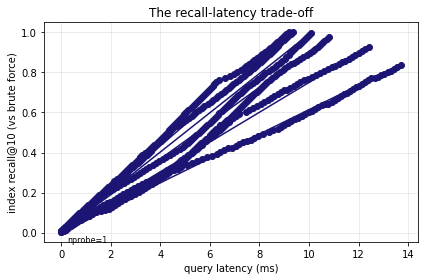

<Figure size 432x288 with 0 Axes>

<Figure size 432x288 with 0 Axes>

<Figure size 432x288 with 0 Axes>

<Figure size 432x288 with 0 Axes>

<Figure size 432x288 with 0 Axes>

<Figure size 432x288 with 0 Axes>

... (589 outputs left out)

<Figure size 432x288 with 0 Axes>

<Figure size 432x288 with 0 Axes>

<Figure size 432x288 with 0 Axes>

<Figure size 432x288 with 0 Axes>

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(res["latency (ms)"], res["recall@10 (vs Flat)"], "o-", color="#1C1573")
for _, r in res.iterrows():    
    ax.annotate(f"nprobe={int(r['nprobe'])}",                
                (r["latency (ms)"], r["recall@10 (vs Flat)"]),                
                textcoords="offset points", xytext=(6, -10), fontsize=8)
    ax.set_xlabel("query latency (ms)")
    ax.set_ylabel("index recall@10 (vs brute force)")
    ax.set_title("The recall-latency trade-off")
    ax.grid(alpha=0.3)
    plt.tight_layout();
    plt.show()

**Read the curve.** 

At `nprobe=1` we scan 1/32 of the corpus — fast, but we miss neighbours. 
At `nprobe=nlist` we have scanned everything, so recall is 1.0 and we have simply re-implemented brute force, more slowly. The useful region is the knee. **This is a knob to be tuned on a validation set — it is nota free parameter.**

## 8. Semantic evaluation — Recall@K, Precision@K, mAP

Now the *other* kind of evaluation: is the **embedding** any good? Same formulae, **different ground truth**. Here relevance = "same UrbanSound8K class as the query". We exclude the query itself from its own
results.

In [13]:
def evaluate(K=10, n_queries=200):    
    qs = np.random.choice(N, n_queries, replace=False)    
    recalls, precisions, aps = [], [], []    
    for i in qs:        
        scores = E @ E[i]        
        scores[i] = -np.inf                       # never retrieve the query itself        
        ranked = np.argsort(-scores)[:K]        
        rel = (label_ids[ranked] == label_ids[i]).astype(int)        
        n_relevant_total = (label_ids == label_ids[i]).sum() - 1        
        recalls.append(rel.sum() / max(n_relevant_total, 1))        
        precisions.append(rel.sum() / K)        # Average Precision: mean of Precision@k at every position that IS relevant        
        if rel.sum() > 0:            
            hits = np.cumsum(rel)            
            prec_at_k = hits / np.arange(1, K + 1)            
            aps.append((prec_at_k * rel).sum() / rel.sum())        
        else:            
            aps.append(0.0)    
    return {f"Recall@{K}": np.mean(recalls),            
            f"Precision@{K}": np.mean(precisions),            
            "mAP": np.mean(aps)}
for K in [1, 5, 10]:    
    print(f"K={K:<3}", {k: round(v, 3) for k, v in evaluate(K=K).items()})

K=1   {'Recall@1': 0.012, 'Precision@1': 0.95, 'mAP': 0.95}
K=5   {'Recall@5': 0.056, 'Precision@5': 0.89, 'mAP': 0.96}
K=10  {'Recall@10': 0.107, 'Precision@10': 0.879, 'mAP': 0.959}


**Two things to notice.**1. 

`Recall@1` looks terrible. It is **capped**: with ~80 relevant clips in the corpus,   a single slot can recover at most 1/80 of them. Recall@K is bounded by   $K / |R_q|$ — a low number here is arithmetic, not failure.2. 

`Precision@K` is the honest measure of whether the neighbours are the right *kind* of   sound. That is the number that tells you the embedding is working.

## 9. Keeping the index fresh

Corpora are not static. Three operations, three different costs.

In [14]:
# ---- INSERT: a new clip arrives -------------------------------------
new_path = meta.loc[10, "path"]                  
# pretend this is a brand-new recording
new_vec  = l2_normalize(embed_clip(new_path).reshape(1, -1)).astype("float32")
if HAS_FAISS:    
    before = index_flat.ntotal    
    index_flat.add(new_vec)    
    print(f"Flat index: {before} -> {index_flat.ntotal} vectors. Cheap: one append.")
else:    
    print("Fallback: append the row to E. Cheap: one append.")
    print()
    print("IVF: the new vector is assigned to its NEAREST EXISTING centroid.")
    print("     The centroids themselves do NOT move. Inserts are cheap --")
    print("     but they slowly degrade the partitioning. This is drift.")

Flat index: 800 -> 801 vectors. Cheap: one append.


In [15]:
# ---- DELETE: tombstoning ---------------------------------------------
# Most ANN indexes cannot truly remove a vector. We mask it instead.

tombstoned = {5, 17, 42}
def search_with_tombstones(q, k=5, overfetch=3):    
    ids, scores = search_flat(q, k * overfetch)        # over-fetch to compensate    
    keep = [(i, s) for i, s in zip(ids, scores) 
            if i not in tombstoned]    
    return keep[:k]

print("Without tombstones:", search_flat(E[5], 5)[0])
print("With tombstones   :", [i for i, _ in search_with_tombstones(E[5], 5)])
print()
print("Note: the deleted vectors still OCCUPY MEMORY and are still SCANNED.")
print("As tombstones accumulate, effective recall drops -> periodic compaction needed.")

Without tombstones: [  5   8 378 151 200]
With tombstones   : [8, 378, 151, 200, 729]

Note: the deleted vectors still OCCUPY MEMORY and are still SCANNED.
As tombstones accumulate, effective recall drops -> periodic compaction needed.


### And the expensive one
**Changing the encoder** (YAMNet -> CLAP, say) defines a **different vector space**. Old and new vectors are *not comparable* — their axes mean different things. There is no partial upgrade. The **entire corpus must be re-embedded** and the index rebuilt from scratch. In Lab 8B we do exactly that: we throw away every YAMNet vector computed here and start again with CLAP.

## 10. What we built, and what it cannot do

We now have a working **audio-to-audio** retrieval system: encode, index, search,evaluate, maintain. But note what the user must supply: **a sound**. To find a sound, you must already*have* a sound.There is no way, with YAMNet or any other audio-only encoder, to turn the sentence *"a siren passing by"* into a vector in this same space. The text simply has nowhere to go.**That is the gap Lab 8B closes.**